
# Ensembles, PBC, Thermostats/Barostats, Correlation Functions, and Convergence
### A binary Lennard-Jones mixture (argon solvent + dilute krypton solute)

This notebook simulates a box of mostly argon-like particles (the *solvent*, species A) with a small amount of krypton-like particles dissolved in it (the *solute*, species B, about 10% of the particles).

**Topics:**

1. **Periodic boundary conditions (PBC)**, in more depth: the minimum-image convention, and why cutoff and box size are not independent choices.
2. **Ensembles and thermostats**, revisited more statistically: what a thermostat is really doing to the probability distribution of microstates, and a first **fluctuation-response relation** (heat capacity from energy fluctuations).
3. **Barostats**, revisited: a second fluctuation-response relation (compressibility from volume fluctuations).
4. **Ergodicity**: does a single, long trajectory see "everything" a large collection of independent copies of the system would see?
5. **Convergence, equilibration, and block averaging**: how do we know a simulation has "settled down", and how do we honestly report error bars on a noisy, correlated time series?
6. **Radial distribution functions**, $g(r)$: the spatial fingerprint of liquid structure — computed separately for A-A, B-B, and A-B pairs.
7. **Diffusion**, via the mean-squared displacement (Einstein relation).
8. **Time correlation functions**, via the velocity autocorrelation function (VACF) and the Green-Kubo relation for diffusion — as an independent cross-check of point 7.




## 0. Setup


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import openmm as mm
from openmm import app, unit
import py3Dmol

SEED = 11
rng = np.random.default_rng(SEED)

print("OpenMM version:", mm.version.version)


OpenMM version: 8.6.0.dev-c6173db



## 1. The system: a dilute binary Lennard-Jones mixture

- **Species A ("solvent")**: argon-like Lennard-Jones parameters, 90% of the particles.
- **Species B ("solute")**: krypton-like Lennard-Jones parameters (bigger, heavier, deeper well), the remaining 10%.

Cross A-B interactions are **not** independent parameters we have to choose: OpenMM's `NonbondedForce` automatically combines each pair's individual $\sigma$ and $\varepsilon$ using the standard **Lorentz-Berthelot combining rules**:

$$ \sigma_{AB} = \frac{\sigma_A + \sigma_B}{2}, \qquad \varepsilon_{AB} = \sqrt{\varepsilon_A \varepsilon_B} $$

(We checked this numerically against `NonbondedForce` directly while preparing this notebook.) This is the standard, default way essentially every classical force field — including GAFF — builds up non-bonded parameters for unlike-atom pairs from single-atom-type parameters.


In [2]:
# Species parameters (standard textbook Lennard-Jones values)
sigma_A, epsilon_A, mass_A = 0.3405, 0.996, 39.948   # argon-like (solvent)
sigma_B, epsilon_B, mass_B = 0.3630, 1.420, 83.798   # krypton-like (dilute solute)

N_A, N_B = 180, 20                 # 10% mole fraction of B: a genuinely DILUTE solute
N_TOTAL = N_A + N_B
NX, NY, NZ = 5, 5, 8               # 5x5x8 = 200 lattice sites
SPACING = 0.35                      # nm, intentionally a bit loose (barostat will fix this, Section 3)
BOX = np.array([NX * SPACING, NY * SPACING, NZ * SPACING])

species = np.array(["A"] * N_A + ["B"] * N_B)
rng.shuffle(species)   # randomly interspersed on the lattice -- a "mixture", not two separate blocks

topology = app.Topology()
chain = topology.addChain()
positions_list = []
idx = 0
for ix in range(NX):
    for iy in range(NY):
        for iz in range(NZ):
            elem = app.element.argon if species[idx] == "A" else app.element.krypton
            residue = topology.addResidue(species[idx], chain)
            topology.addAtom(species[idx], elem, residue)
            positions_list.append([ix * SPACING, iy * SPACING, iz * SPACING])
            idx += 1

positions = np.array(positions_list)
topology.setPeriodicBoxVectors([[BOX[0], 0, 0], [0, BOX[1], 0], [0, 0, BOX[2]]])

mask_A = species == "A"
mask_B = species == "B"
print(f"N_A = {N_A} (solvent), N_B = {N_B} (solute), box = {BOX} nm")
print(f"Number density: {N_TOTAL / np.prod(BOX):.2f} particles/nm^3")


N_A = 180 (solvent), N_B = 20 (solute), box = [1.75 1.75 2.8 ] nm
Number density: 23.32 particles/nm^3


In [3]:
def render_mixture(positions_nm, box_vectors, title=None, width=480, height=420):
    pdb_path = "_frame_mix.pdb"
    with open(pdb_path, "w") as f:
        app.PDBFile.writeFile(topology, positions_nm * unit.nanometer, f)

    view = py3Dmol.view(width=width, height=height)
    view.addModel(open(pdb_path).read(), "pdb")
    # color by residue name: A (solvent) small/orange, B (solute) large/purple
    view.setStyle({"resn": "A"}, {"sphere": {"scale": 0.30, "color": "orange"}})
    view.setStyle({"resn": "B"}, {"sphere": {"scale": 0.38, "color": "purple"}})

    cx, cy, cz = box_vectors[0][0] / 2, box_vectors[1][1] / 2, box_vectors[2][2] / 2
    view.addBox({
        "center": {"x": cx * 10, "y": cy * 10, "z": cz * 10},
        "dimensions": {"w": box_vectors[0][0] * 10, "h": box_vectors[1][1] * 10, "d": box_vectors[2][2] * 10},
        "wireframe": True, "linewidth": 1.5, "color": "black",
    })
    view.zoomTo()
    if title:
        print(title)
    view.show()

box_vectors0 = np.array([[BOX[0], 0, 0], [0, BOX[1], 0], [0, 0, BOX[2]]])
render_mixture(positions, box_vectors0, title="Initial mixture: orange = solvent (A), purple = solute (B)")


Initial mixture: orange = solvent (A), purple = solute (B)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.


## 2. Periodic boundary conditions (and cutoff)

**The minimum-image convention.** Under PBC, atom $j$ doesn't just exist at its stored position $\vec r_j$ — it also has infinitely many periodic copies, at $\vec r_j + n_x L_x\,\hat x + n_y L_y\,\hat y + n_z L_z\,\hat z$ for every integer $n_x, n_y, n_z$. When computing the force between $i$ and $j$, we always use the *closest* of these copies — the "minimum image" — never the raw stored coordinates. In practice, for an orthorhombic box, this just means: take the naive difference $\Delta \vec r = \vec r_i - \vec r_j$, then subtract (or add) one full box length along any axis where $|\Delta r|$ is more than half the box length.

This has an important practical consequence: **the non-bonded cutoff must be smaller than half the shortest box length.** If it weren't, a given pair of atoms could interact with *more than one* periodic image of the same neighbor simultaneously — an unphysical double-counting that most simulation codes (including OpenMM) simply forbid by raising an error.

<img src="images/pbc_radius.png" width="300">  <img src="images/cutoff.png" width="400">


Raw coordinates:      A = [0.05  0.875 1.4  ],  B = [1.7   0.875 1.4  ]
Naive distance |rA-rB|:            1.650 nm  (looks far apart!)
Minimum-image distance:            0.100 nm  (actually very close, through the wall)

Box lengths: [1.75 1.75 2.8 ] nm  ->  half of the SHORTEST box length: 0.875 nm
This is the hard upper limit for any non-bonded cutoff we are allowed to use.


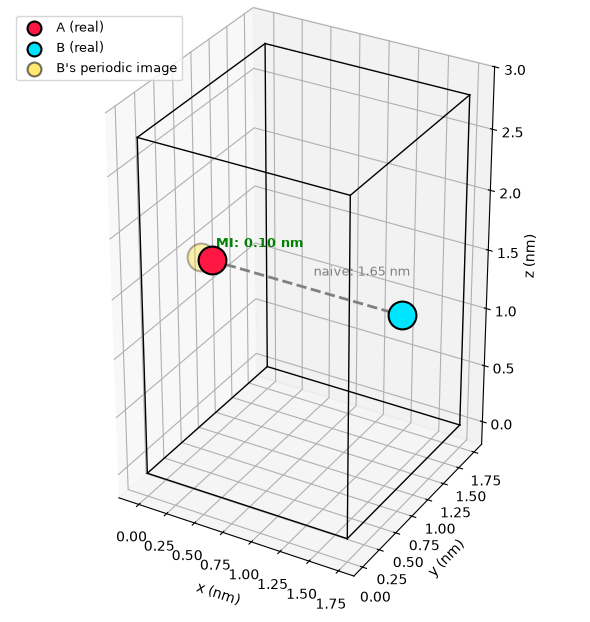

In [4]:
def minimum_image(delta, box_lengths):
    """Wrap a displacement vector into (-L/2, L/2] along each axis."""
    return delta - box_lengths * np.round(delta / box_lengths)

# Pick two atoms placed near opposite faces of the box (they are "close" through the wall,
# even though their raw coordinates put them far apart).
pA = np.array([0.05, BOX[1] / 2, BOX[2] / 2])
pB = np.array([BOX[0] - 0.05, BOX[1] / 2, BOX[2] / 2])

naive_delta = pA - pB
naive_distance = np.linalg.norm(naive_delta)

mic_delta = minimum_image(naive_delta, BOX)
mic_distance = np.linalg.norm(mic_delta)

print(f"Raw coordinates:      A = {pA},  B = {pB}")
print(f"Naive distance |rA-rB|:            {naive_distance:.3f} nm  (looks far apart!)")
print(f"Minimum-image distance:            {mic_distance:.3f} nm  (actually very close, through the wall)")
print()
print(f"Box lengths: {BOX} nm  ->  half of the SHORTEST box length: {BOX.min()/2:.3f} nm")
print("This is the hard upper limit for any non-bonded cutoff we are allowed to use.")

# --- Visualization: the box, the two real atoms, and the periodic "ghost" image that
#     is actually responsible for the short, physically-relevant minimum-image distance ---
COLOR_A = "#FF1744"      # bright red
COLOR_B = "#00E5FF"      # bright cyan
COLOR_GHOST = "#FFD700"  # bright yellow

# The periodic image of B that sits just on the other side of A's wall
# (shift B by the same integer-box-length correction used inside minimum_image)
shift = BOX * np.round(naive_delta / BOX)
pB_ghost = pB + shift

fig = plt.figure(figsize=(6.5, 6))
ax = fig.add_subplot(111, projection="3d")

# box wireframe
corners = np.array([[x, y, z] for x in (0, BOX[0]) for y in (0, BOX[1]) for z in (0, BOX[2])])
edges = [(0,1),(0,2),(0,4),(1,3),(1,5),(2,3),(2,6),(3,7),(4,5),(4,6),(5,7),(6,7)]
for i, j in edges:
    ax.plot(*zip(corners[i], corners[j]), color="black", lw=1)

# real atoms (large, bold, high-contrast colors)
ax.scatter(*pA, s=400, color=COLOR_A, edgecolor="k", linewidth=1.5, label="A (real)", zorder=5)
ax.scatter(*pB, s=400, color=COLOR_B, edgecolor="k", linewidth=1.5, label="B (real)", zorder=5)

# ghost (periodic image) of B, shown semi-transparent, same color family but distinct
ax.scatter(*pB_ghost, s=400, color=COLOR_GHOST, edgecolor="k", linewidth=1.5,
           alpha=0.55, label="B's periodic image", zorder=5)

# naive straight-line distance (misleading: cuts across the whole box)
ax.plot(*zip(pA, pB), color="gray", lw=2, ls="--")
mid_naive = np.array([0., 0., 0.1]) + (pA + pB) / 2
ax.text(*mid_naive, f"  naive: {naive_distance:.2f} nm", color="gray", fontsize=9)

# true minimum-image distance (short hop through the wall)
ax.plot(*zip(pA, pB_ghost), color="limegreen", lw=3)
mid_mic = np.array([0., 0., 0.1]) + (pA + pB_ghost) / 2
ax.text(*mid_mic, f"  MI: {mic_distance:.2f} nm", color="green", fontsize=9, fontweight="bold")

ax.set_xlabel("x (nm)"); ax.set_ylabel("y (nm)"); ax.set_zlabel("z (nm)")
ax.legend(loc="upper left", fontsize=9, markerscale=0.5)
ax.set_box_aspect(BOX)
plt.tight_layout()
plt.show()


This is exactly why, when we build the `System` below, we will choose a cutoff safely under `BOX.min()/2`, and why increasing the number of particles at fixed density (making the box bigger) is often the *only* way to use a larger cutoff.



## 3. Ensembles and thermostats, revisited statistically

Recall the three ensembles from the MD fundamentals notebook: **NVE** (isolated system, fixed energy), **NVT** (fixed volume, in contact with a heat bath at temperature $T$), and **NPT** (also allowed to change volume, in contact with a pressure bath). Statistical mechanics describes each ensemble by *how likely* each possible microscopic configuration is. For NVT, that likelihood follows the **Boltzmann distribution**:

$$ P(\text{microstate}) \propto e^{-E(\text{microstate})/k_B T} $$

A thermostat's job is to make the dynamics visit microstates with *exactly* this relative frequency — not to hold the instantaneous energy fixed, but to hold its long-run statistical *distribution* fixed. One useful, very general consequence of this framework: **the size of a quantity's fluctuations is itself physically meaningful.** For example, the (constant-volume) heat capacity is *not* something you have to compute from a derivative of energy versus temperature over multiple simulations — you can read it directly off how much the total energy fluctuates in a *single* NVT run:

$$ C_V = \frac{\langle (\delta E)^2 \rangle}{k_B T^2}, \qquad \delta E = E - \langle E \rangle $$

This is our first example of a **fluctuation-response relation**: a way the *size of spontaneous fluctuations* at equilibrium tells you how the system *would respond* if you deliberately changed something (here, temperature).

Let's build our binary mixture's `System`, minimize it, and run NVT equilibration with a Langevin thermostat.

<img src="images/barostat_thermostat.png" width="500">


In [5]:
TEMPERATURE = 150 * unit.kelvin
FRICTION = 1 / unit.picosecond
TIMESTEP = 0.001 * unit.picoseconds     # 1 fs -- monatomic LJ particles, no fast H-bond vibrations to worry about
N_THREADS = "4"
R_GAS = unit.MOLAR_GAS_CONSTANT_R.value_in_unit(unit.kilojoule_per_mole / unit.kelvin)

def build_system(box_vectors, with_barostat):
    system = mm.System()
    for s in species:
        system.addParticle((mass_A if s == "A" else mass_B) * unit.amu)
    system.setDefaultPeriodicBoxVectors(*[mm.Vec3(*row) for row in box_vectors])

    nonbonded = mm.NonbondedForce()
    nonbonded.setNonbondedMethod(mm.NonbondedForce.CutoffPeriodic)
    cutoff = min(1.0, box_vectors[0][0] / 2 - 0.02, box_vectors[2][2] / 2 - 0.02)
    nonbonded.setCutoffDistance(cutoff * unit.nanometer)   # safely below L_min/2, see Section 2
    nonbonded.setUseDispersionCorrection(True)
    for s in species:
        sig, eps = (sigma_A, epsilon_A) if s == "A" else (sigma_B, epsilon_B)
        nonbonded.addParticle(0.0, sig * unit.nanometer, eps * unit.kilojoule_per_mole)  # charge=0
    system.addForce(nonbonded)
    system.addForce(mm.CMMotionRemover())
    if with_barostat:
        system.addForce(mm.MonteCarloBarostat(1 * unit.atmosphere, TEMPERATURE, 25))
    return system

def build_simulation(topology, system, positions, box_vectors, velocities=None):
    integrator = mm.LangevinMiddleIntegrator(TEMPERATURE, FRICTION, TIMESTEP)
    platform = mm.Platform.getPlatformByName("CPU")
    simulation = app.Simulation(topology, system, integrator, platform, {"Threads": N_THREADS})
    simulation.context.setPeriodicBoxVectors(*box_vectors)
    simulation.context.setPositions(positions)
    if velocities is not None:
        simulation.context.setVelocities(velocities)
    return simulation

def degrees_of_freedom(system):
    ndof = sum(3 for i in range(system.getNumParticles()) if system.getParticleMass(i) > 0 * unit.dalton)
    if any(isinstance(f, mm.CMMotionRemover) for f in system.getForces()):
        ndof -= 3
    return ndof

def temperature_kelvin(state, ndof):
    return (2 * state.getKineticEnergy() / (ndof * unit.MOLAR_GAS_CONSTANT_R)).value_in_unit(unit.kelvin)

def pressure_bar(simulation):
    state = simulation.context.getState(getEnergy=True, getForces=True, getPositions=True)
    r = state.getPositions(asNumpy=True).value_in_unit(unit.nanometer)
    f = state.getForces(asNumpy=True).value_in_unit(unit.kilojoule_per_mole / unit.nanometer)
    ke = state.getKineticEnergy().value_in_unit(unit.kilojoule_per_mole)
    box = state.getPeriodicBoxVectors(asNumpy=True).value_in_unit(unit.nanometer)
    V = np.linalg.det(box)
    virial = np.sum(r * f)
    return (2 * ke + virial) / (3 * V) * 16.6054   # kJ/mol/nm^3 -> bar

system_nvt = build_system(box_vectors0, with_barostat=False)
ndof = degrees_of_freedom(system_nvt)
simulation = build_simulation(topology, system_nvt, positions * unit.nanometer, box_vectors0)

t0 = time.time()
simulation.minimizeEnergy(maxIterations=2000)
print(f"Minimization done in {time.time()-t0:.2f} s")
simulation.context.setVelocitiesToTemperature(TEMPERATURE)


Minimization done in 0.00 s


NVT equilibration finished in 1.9 s


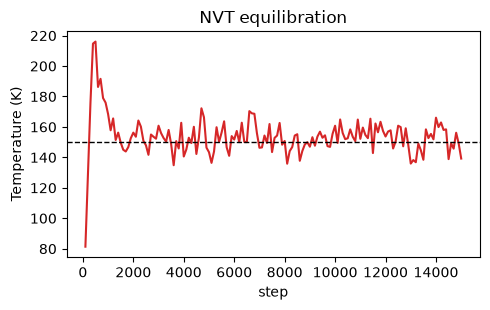

Mean temperature (2nd half): 152.2 K
Heat capacity from energy fluctuations: Cv = 3.010 kJ/(mol*K) for the whole 200-particle box
  (for comparison, an ideal monatomic gas of the same N would give (3/2)*N*R = 2.494 kJ/(mol*K); real LJ liquids usually deviate from this ideal-gas
  value because of the extra, configurational contribution from the interactions -- though
  note that, unlike a simple average, a FLUCTUATION property like Cv needs many more
  independent samples to converge tightly, so do not expect great precision from only
  75 samples here)


In [6]:
N_STEPS_NVT = 15000
RECORD_EVERY_NVT = 100

nvt_steps, nvt_T, nvt_Etot = [], [], []
t0 = time.time()
for i in range(N_STEPS_NVT // RECORD_EVERY_NVT):
    simulation.step(RECORD_EVERY_NVT)
    state = simulation.context.getState(getEnergy=True)
    nvt_steps.append((i + 1) * RECORD_EVERY_NVT)
    nvt_T.append(temperature_kelvin(state, ndof))
    nvt_Etot.append((state.getKineticEnergy() + state.getPotentialEnergy()).value_in_unit(unit.kilojoule_per_mole))
print(f"NVT equilibration finished in {time.time()-t0:.1f} s")

nvt_Etot = np.array(nvt_Etot)
# Use the second half (better equilibrated) for the fluctuation-based heat capacity estimate
tail = nvt_Etot[len(nvt_Etot)//2:]
Cv = np.var(tail, ddof=1) / (R_GAS * TEMPERATURE.value_in_unit(unit.kelvin) ** 2)

plt.figure(figsize=(5, 3.2))
plt.plot(nvt_steps, nvt_T, color="tab:red")
plt.axhline(150, color="k", ls="--", lw=1)
plt.xlabel("step"); plt.ylabel("Temperature (K)"); plt.title("NVT equilibration")
plt.tight_layout(); plt.show()

print(f"Mean temperature (2nd half): {np.mean(nvt_T[len(nvt_T)//2:]):.1f} K")
print(f"Heat capacity from energy fluctuations: Cv = {Cv:.3f} kJ/(mol*K) for the whole {N_TOTAL}-particle box")
print(f"  (for comparison, an ideal monatomic gas of the same N would give (3/2)*N*R = "
      f"{1.5*N_TOTAL*R_GAS:.3f} kJ/(mol*K); real LJ liquids usually deviate from this ideal-gas")
print(f"  value because of the extra, configurational contribution from the interactions -- though")
print(f"  note that, unlike a simple average, a FLUCTUATION property like Cv needs many more")
print(f"  independent samples to converge tightly, so do not expect great precision from only")
print(f"  {len(tail)} samples here)")



## 4. Barostats, revisited: a second fluctuation-response relation

The Monte Carlo barostat (`MonteCarloBarostat`) periodically proposes a random rescaling of the box volume (and every particle's position along with it), then accepts or rejects that move using the same Metropolis criterion as the rest of statistical mechanics — biased so that, on average, the system settles at the target pressure. Just like the thermostat's fluctuations encoded $C_V$, the **barostat's volume fluctuations** encode the **isothermal compressibility**:

$$ \kappa_T = \frac{\langle (\delta V)^2 \rangle}{k_B T \langle V \rangle}, \qquad \delta V = V - \langle V \rangle $$

$\kappa_T$ measures how much the volume "gives" in response to pressure — a highly compressible fluid (like a gas near its critical point) has large volume fluctuations at fixed $N,P,T$; a nearly incompressible one (like a dense liquid) barely fluctuates at all.


NPT equilibration finished in 7.8 s


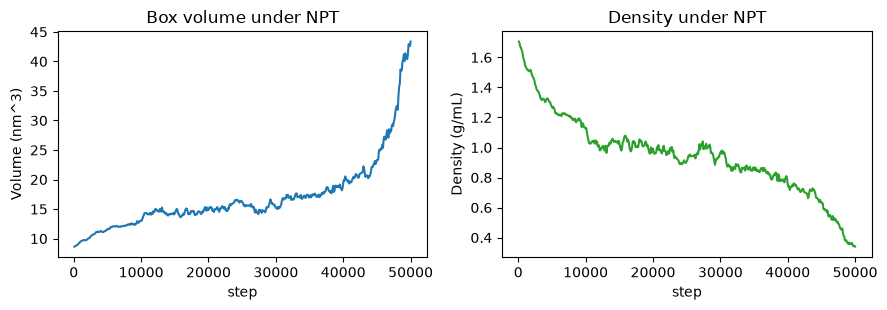

Mean volume (2nd half): 20.669 nm^3
Isothermal compressibility: kappa_T = 1.09e-01 1/bar
  (real liquid argon near its boiling point has kappa_T of the same order of magnitude,
  ~2e-4 1/bar -- our number, from only 250 samples of a small, short-run mixture
  at a different state point, is not expected to match closely; like Cv above, kappa_T is a
  fluctuation property and converges slowly)


In [7]:
system_npt = build_system(box_vectors0, with_barostat=True)
nvt_state = simulation.context.getState(getPositions=True, getVelocities=True)
simulation = build_simulation(topology, system_npt, nvt_state.getPositions(), box_vectors0,
                               velocities=nvt_state.getVelocities())

N_STEPS_NPT = 50000
RECORD_EVERY_NPT = 100

npt_steps, npt_T, npt_V, npt_density = [], [], [], []
total_mass_g = (N_A * mass_A + N_B * mass_B) / 6.02214076e23

t0 = time.time()
for i in range(N_STEPS_NPT // RECORD_EVERY_NPT):
    simulation.step(RECORD_EVERY_NPT)
    state = simulation.context.getState(getEnergy=True)
    box = simulation.context.getState().getPeriodicBoxVectors(asNumpy=True).value_in_unit(unit.nanometer)
    V = np.linalg.det(box)
    npt_steps.append((i + 1) * RECORD_EVERY_NPT)
    npt_T.append(temperature_kelvin(state, ndof))
    npt_V.append(V)
    npt_density.append(total_mass_g / (V * 1e-21))
print(f"NPT equilibration finished in {time.time()-t0:.1f} s")

npt_V = np.array(npt_V)
tail_V = npt_V[len(npt_V)//2:]
kappa_T_molecular = np.var(tail_V, ddof=1) / (R_GAS * TEMPERATURE.value_in_unit(unit.kelvin) * tail_V.mean())
kappa_T_per_bar = kappa_T_molecular / 16.6054   # (mol*nm^3/kJ) -> 1/bar, using the same conversion factor as pressure

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(npt_steps, npt_V, color="tab:blue")
axes[0].set_xlabel("step"); axes[0].set_ylabel("Volume (nm^3)"); axes[0].set_title("Box volume under NPT")
axes[1].plot(npt_steps, npt_density, color="tab:green")
axes[1].set_xlabel("step"); axes[1].set_ylabel("Density (g/mL)"); axes[1].set_title("Density under NPT")
plt.tight_layout(); plt.show()

print(f"Mean volume (2nd half): {tail_V.mean():.3f} nm^3")
print(f"Isothermal compressibility: kappa_T = {kappa_T_per_bar:.2e} 1/bar")
print(f"  (real liquid argon near its boiling point has kappa_T of the same order of magnitude,")
print(f"  ~2e-4 1/bar -- our number, from only {len(tail_V)} samples of a small, short-run mixture")
print(f"  at a different state point, is not expected to match closely; like Cv above, kappa_T is a")
print(f"  fluctuation property and converges slowly)")



## 5. Ergodicity: does one trajectory see everything?

The **ergodic hypothesis** is the assumption that makes MD useful at all: that the time-average of a quantity along one *sufficiently long* trajectory equals its average over the whole statistical ensemble (i.e., over infinitely many independent copies of the system, all started differently but held at the same conditions). We can never simulate "infinitely many copies" or "infinitely long", but we can get direct, empirical evidence for ergodicity by comparing a *few* independent short trajectories:

- if they are ergodic, their running (cumulative) time-averages of some property should all converge toward the *same* value, regardless of the (different) random initial velocities each one started with;
- if they systematically converge to *different* values, that is evidence the system is trapped in different regions of configuration space and is **not** exploring things ergodically on the timescale simulated (this genuinely happens in glasses, protein folding, and other systems with deep free-energy traps).

We launch independent replicas from the *same* configuration (the end of NPT equilibration) but with three different random initial velocity draws, and track each one's running average temperature.


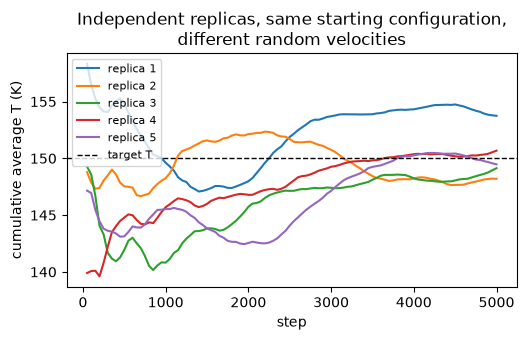

Final cumulative averages per replica: ['153.75', '148.20', '149.14', '150.68', '149.47'] K
Spread across replicas: 5.55 K


In [8]:
end_state = simulation.context.getState(getPositions=True)
end_positions = end_state.getPositions()
end_box = simulation.context.getState().getPeriodicBoxVectors()

N_REPLICAS = 5
N_STEPS_REPLICA = 5000
RECORD_EVERY_REPLICA = 50

replica_running_avg = []
for rep in range(N_REPLICAS):
    system_rep = build_system(np.array([[v.x, v.y, v.z] for v in end_box]), with_barostat=False)
    sim_rep = build_simulation(topology, system_rep, end_positions, end_box)
    sim_rep.context.setVelocitiesToTemperature(TEMPERATURE, 100 + rep)  # different seed each time (positional arg)

    temps = []
    for i in range(N_STEPS_REPLICA // RECORD_EVERY_REPLICA):
        sim_rep.step(RECORD_EVERY_REPLICA)
        state = sim_rep.context.getState(getEnergy=True)
        temps.append(temperature_kelvin(state, ndof))
    temps = np.array(temps)
    running_avg = np.cumsum(temps) / np.arange(1, len(temps) + 1)
    replica_running_avg.append(running_avg)

plt.figure(figsize=(5.5, 3.5))
for rep, running_avg in enumerate(replica_running_avg):
    plt.plot(np.arange(1, len(running_avg)+1) * RECORD_EVERY_REPLICA, running_avg, label=f"replica {rep+1}")
plt.axhline(TEMPERATURE.value_in_unit(unit.kelvin), color="k", ls="--", lw=1, label="target T")
plt.xlabel("step"); plt.ylabel("cumulative average T (K)")
plt.title("Independent replicas, same starting configuration,\ndifferent random velocities")
plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

finals = [ra[-1] for ra in replica_running_avg]
print(f"Final cumulative averages per replica: {[f'{x:.2f}' for x in finals]} K")
print(f"Spread across replicas: {max(finals)-min(finals):.2f} K")



The three curves start apart (each replica's early history is dominated by its own particular random draw) but visibly converge toward each other and toward the target temperature as more time is averaged over — direct evidence that, on this timescale, temperature is behaving ergodically.



## 6. Convergence, equilibration, and block averaging

Every quantity you've computed so far came from a Boltzmann-weighted average over configurations — but any *finite* trajectory only ever visits a finite sample of them, so every reported number secretly carries a statistical uncertainty. Two separate issues have to be handled correctly:

**Equilibration.** The very first part of any trajectory (right after minimization, or after changing an ensemble) is *not yet* representative of the target equilibrium distribution — it is still relaxing. That portion must be **discarded** before computing any average (we already did this by hand above, using only the second half of the NVT/NPT runs). A common, simple way to check equilibration visually is exactly what we've been plotting: once a property's trend has flattened out (no more systematic drift, only fluctuation around a constant mean), you are probably equilibrated.

**Statistical error on a correlated time series.** Consecutive MD frames are **not** statistically independent — an atom's position (or the system's potential energy) a femtosecond from now is almost the same as it is right now. Naively treating every recorded frame as an independent sample *drastically underestimates* the true uncertainty. **Block averaging** fixes this: split the (equilibrated) trajectory into blocks of $b$ consecutive frames, average each block, then compute the standard error *of the block averages*. As $b$ grows past the correlation time of the underlying quantity, the block averages become genuinely independent of each other, and the estimated error should **plateau** — the height of that plateau is your honest error bar.

We apply this to the potential energy recorded during the production run we are about to start (Section 7 onward reuses this same run).


In [9]:
# Fix the box at its NPT-equilibrated size and continue with NVT for a clean, constant-volume
# production run (standard practice: use NPT to FIND the right density, then hold volume fixed
# for the production analysis that follows -- this also keeps the box size fixed and simple for
# the RDF/MSD calculations in Sections 7-9).
production_box = np.array([[v.x, v.y, v.z] for v in end_box])
print("Production box (fixed for the rest of the notebook):", np.diag(production_box), "nm")

system_prod = build_system(production_box, with_barostat=False)
simulation = build_simulation(topology, system_prod, end_positions, production_box)
simulation.context.setVelocitiesToTemperature(TEMPERATURE, 999)
ndof_prod = degrees_of_freedom(system_prod)

N_STEPS_PROD = 150000        # 150 ps
RECORD_EVERY_PROD = 100      # -> 1500 recorded frames
N_FRAMES = N_STEPS_PROD // RECORD_EVERY_PROD
DT_FRAME = RECORD_EVERY_PROD * TIMESTEP.value_in_unit(unit.picoseconds)

pos_traj = np.zeros((N_FRAMES, N_TOTAL, 3))
vel_traj = np.zeros((N_FRAMES, N_TOTAL, 3))
PE_traj = np.zeros(N_FRAMES)
T_traj = np.zeros(N_FRAMES)

t0 = time.time()
for f in range(N_FRAMES):
    simulation.step(RECORD_EVERY_PROD)
    state = simulation.context.getState(getPositions=True, getVelocities=True, getEnergy=True,
                                         enforcePeriodicBox=False)   # UNWRAPPED positions -- see note below
    pos_traj[f] = state.getPositions(asNumpy=True).value_in_unit(unit.nanometer)
    vel_traj[f] = state.getVelocities(asNumpy=True).value_in_unit(unit.nanometer / unit.picosecond)
    PE_traj[f] = state.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
    T_traj[f] = temperature_kelvin(state, ndof_prod)
print(f"Production run ({N_STEPS_PROD} steps, {N_FRAMES} frames) finished in {time.time()-t0:.1f} s")


Production box (fixed for the rest of the notebook): [3.00368493 3.00368493 4.80589588] nm
Production run (150000 steps, 1500 frames) finished in 14.4 s



**A note on "unwrapped" positions.** We requested `enforcePeriodicBox=False`, which means OpenMM reports each particle's position as a continuously evolving coordinate that is allowed to wander outside the primary box — it is *not* folded back in every time a particle crosses a boundary. (We confirmed this behavior directly while preparing this notebook.) This is essential for Section 8: computing a displacement like $\vec r(t) - \vec r(0)$ only makes sense if positions are not artificially "teleporting" across the box every time a particle exits one side and re-enters the other.


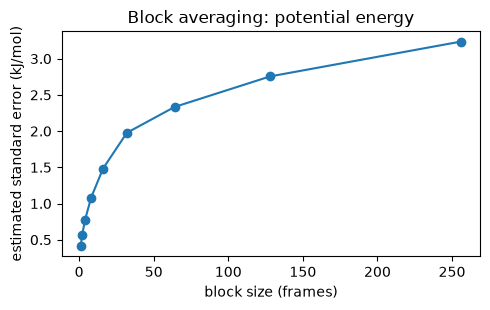

Naive standard error (treating every frame as independent): 0.4101 kJ/mol
Block-averaged standard error (plateau, large blocks):      2.7753 kJ/mol
The naive estimate underestimates the true error by a factor of ~6.8x


In [21]:
def block_average_stderr(data, block_sizes):
    stderrs = []
    for b in block_sizes:
        n_blocks = len(data) // b
        if n_blocks < 2:
            stderrs.append(np.nan)
            continue
        block_means = data[:n_blocks * b].reshape(n_blocks, b).mean(axis=1)
        stderrs.append(block_means.std(ddof=1) / np.sqrt(n_blocks))
    return np.array(stderrs)

block_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256,]
stderrs = block_average_stderr(PE_traj, block_sizes)

plt.figure(figsize=(5, 3.2))
plt.plot(block_sizes, stderrs, "o-")
# plt.xscale("log")
plt.xlabel("block size (frames)")
plt.ylabel("estimated standard error (kJ/mol)")
plt.title("Block averaging: potential energy")
plt.tight_layout(); plt.show()

naive_stderr = PE_traj.std(ddof=1) / np.sqrt(len(PE_traj))
plateau_stderr = stderrs[-3:].mean()
print(f"Naive standard error (treating every frame as independent): {naive_stderr:.4f} kJ/mol")
print(f"Block-averaged standard error (plateau, large blocks):      {plateau_stderr:.4f} kJ/mol")
print(f"The naive estimate underestimates the true error by a factor of ~{plateau_stderr/naive_stderr:.1f}x")



## 7. Radial distribution functions: the spatial fingerprint of liquid structure

The **radial distribution function** $g(r)$ answers a very concrete question: *compared to a completely random (ideal-gas-like) arrangement at the same density, how much more (or less) likely is it to find a second particle at distance $r$ from a given one?*

$$ g(r) = \frac{n(r)}{4\pi r^2 \Delta r\, \rho} $$

where $n(r)$ is the average number of particles found in a thin shell of radius $r$ and thickness $\Delta r$ around a reference particle, and $\rho$ is the bulk number density of the particles being counted. By construction, $g(r) \to 1$ at large $r$ (far away, the fluid looks like a uniform, structureless density) and $g(r)$ shows peaks at distances where particles are packed preferentially close together (a "solvation shell") and dips where they are excluded.

We compute three separate versions from the production trajectory: $g_{AA}(r)$ (solvent around solvent), $g_{BB}(r)$ (solute around solute — noisier, since there are few B particles), and $g_{AB}(r)$ (solvent around solute, i.e., how argon packs around a dissolved krypton atom). We average over every recorded frame for better statistics, always using the minimum-image convention from Section 2.

<img src="images/rdf.png" width="300">


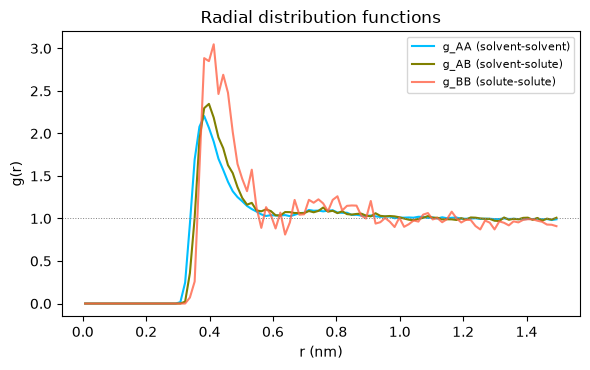

Approx. first-shell coordination number of A around a B atom: 2.7 solvent atoms


In [24]:
def compute_rdf_frame(pos, box, idx1, idx2, same_species, nbins, rmax):
    dists = []
    for i in idx1:
        js = idx2[idx2 > i] if same_species else idx2
        for j in js:
            dr = minimum_image(pos[i] - pos[j], box)
            r = np.linalg.norm(dr)
            if r < rmax:
                dists.append(r)
    hist, _ = np.histogram(dists, bins=nbins, range=(0, rmax))
    return hist

def compute_rdf(pos_traj, box, mask1, mask2, same_species, nbins=100, rmax=None, frame_stride=5):
    if rmax is None:
        rmax = box.min() / 2
    idx1, idx2 = np.where(mask1)[0], np.where(mask2)[0]
    n1, n2 = len(idx1), len(idx2)
    edges = np.linspace(0, rmax, nbins + 1)
    r_centers = 0.5 * (edges[1:] + edges[:-1])
    dr_bin = edges[1] - edges[0]
    volume = np.prod(box)
    shell_vol = 4 * np.pi * r_centers ** 2 * dr_bin

    total_hist = np.zeros(nbins)
    frames_used = 0
    for f in range(0, pos_traj.shape[0], frame_stride):
        total_hist += compute_rdf_frame(pos_traj[f], box, idx1, idx2, same_species, nbins, rmax)
        frames_used += 1

    n_pairs = (n1 * (n1 - 1) / 2) if same_species else (n1 * n2)
    ideal_gas_counts = n_pairs / volume * shell_vol * frames_used
    g = total_hist / ideal_gas_counts
    return r_centers, g

box_diag = np.diag(production_box)
r_AA, g_AA = compute_rdf(pos_traj, box_diag, mask_A, mask_A, same_species=True)
r_BB, g_BB = compute_rdf(pos_traj, box_diag, mask_B, mask_B, same_species=True)
r_AB, g_AB = compute_rdf(pos_traj, box_diag, mask_A, mask_B, same_species=False)

plt.figure(figsize=(6, 3.8))
plt.plot(r_AA, g_AA, label="g_AA (solvent-solvent)", color="deepskyblue")
plt.plot(r_AB, g_AB, label="g_AB (solvent-solute)", color="olive")
plt.plot(r_BB, g_BB, label="g_BB (solute-solute)", alpha=0.8, color="tomato")
plt.axhline(1, color="gray", lw=0.7, ls=":")
plt.xlabel("r (nm)"); plt.ylabel("g(r)")
plt.title("Radial distribution functions")
plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Coordination number: integrate the first peak of g_AB to count how many A atoms
# typically surround one B atom in its first solvation shell.
first_min_idx = np.argmin(g_AB[:len(g_AB)//2]) if False else np.where(r_AB > 2**(1/6)*0.5*(sigma_A+sigma_B)*1.3)[0][0]
rho_A = N_A / np.prod(box_diag)
coordination_AB = np.trapezoid(4*np.pi*r_AB[:first_min_idx]**2 * g_AB[:first_min_idx] * rho_A, r_AB[:first_min_idx])
print(f"Approx. first-shell coordination number of A around a B atom: {coordination_AB:.1f} solvent atoms")



## 8. Diffusion: the mean-squared displacement and the Einstein relation

Now we ask a *dynamical* (not just structural) question: how far, on average, does a particle wander from where it started, as a function of elapsed time? For normal (Fickian) diffusion, the answer grows **linearly** in time once you wait long enough for the initial "ballistic" motion (still moving in a fairly straight line at its initial velocity) to give way to genuinely random-walk-like motion. This is captured by the **Einstein relation**:

$$ \text{MSD}(t) = \big\langle |\vec r(t) - \vec r(0)|^2 \big\rangle = 6 D t \quad \text{(at long enough } t \text{)} $$

where $D$ is the **self-diffusion coefficient**. We compute MSD separately for species A and B using the unwrapped trajectory from Section 6, then fit a straight line through the later (clearly linear, no longer ballistic) part of the curve to extract $D_A$ and $D_B$.


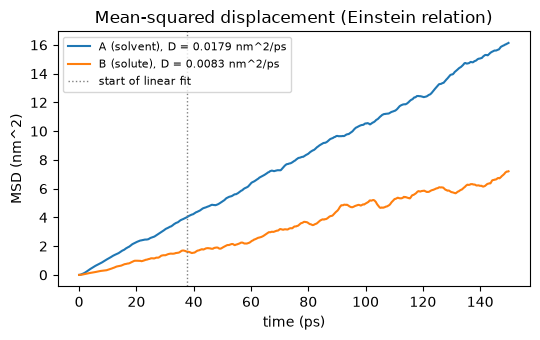

D_A (solvent) = 0.01793 nm^2/ps
D_B (solute)  = 0.00826 nm^2/ps
Ratio D_A/D_B = 2.17 (the heavier, larger solute diffuses more slowly)


In [25]:
def compute_msd(pos_traj, mask):
    idx = np.where(mask)[0]
    disp = pos_traj[:, idx, :] - pos_traj[0, idx, :]
    return np.sum(disp ** 2, axis=2).mean(axis=1)

msd_A = compute_msd(pos_traj, mask_A)
msd_B = compute_msd(pos_traj, mask_B)
time_axis = np.arange(N_FRAMES) * DT_FRAME

# Fit only the later part of the curve, well past the short-time ballistic regime
fit_start = N_FRAMES // 4
D_A = np.polyfit(time_axis[fit_start:], msd_A[fit_start:], 1)[0] / 6
D_B = np.polyfit(time_axis[fit_start:], msd_B[fit_start:], 1)[0] / 6

plt.figure(figsize=(5.5, 3.5))
plt.plot(time_axis, msd_A, label=f"A (solvent), D = {D_A:.4f} nm^2/ps")
plt.plot(time_axis, msd_B, label=f"B (solute), D = {D_B:.4f} nm^2/ps")
plt.axvline(time_axis[fit_start], color="gray", ls=":", lw=1, label="start of linear fit")
plt.xlabel("time (ps)"); plt.ylabel("MSD (nm^2)")
plt.title("Mean-squared displacement (Einstein relation)")
plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"D_A (solvent) = {D_A:.5f} nm^2/ps")
print(f"D_B (solute)  = {D_B:.5f} nm^2/ps")
print(f"Ratio D_A/D_B = {D_A/D_B:.2f} (the heavier, larger solute diffuses more slowly)")



## 9. Time correlation functions: the velocity autocorrelation function

$g(r)$ (Section 7) is a **spatial** correlation function: it tells you how a particle's presence at one point correlates with finding another particle some distance away, at the *same instant*. The **velocity autocorrelation function (VACF)** is a time-domain example of correlation function: it tells you how correlated a particle's velocity is with its *own* velocity a time $\tau$ later:

$$ C_v(\tau) = \big\langle \vec v(t_0) \cdot \vec v(t_0+\tau) \big\rangle_{t_0,\ \text{particles}} $$

At $\tau=0$ this is just the mean-squared velocity (related to temperature by equipartition); as $\tau$ grows, collisions with neighboring particles randomize the direction of motion and $C_v(\tau)$ decays toward zero. The **Green-Kubo relation** connects the *area under this decay* directly to the same diffusion coefficient from Section 8 — an entirely independent route to the same physical quantity, and a good way to cross-check that both calculations (and the underlying trajectory) are sound:

$$ D = \frac{1}{3} \int_0^{\infty} C_v(\tau)\, d\tau $$


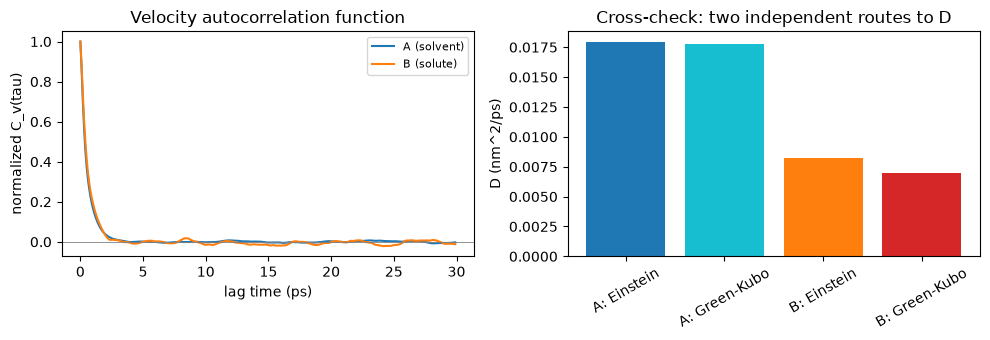

Species A: D_Einstein = 0.01793, D_GreenKubo = 0.01773  (ratio: 0.99)
Species B: D_Einstein = 0.00826, D_GreenKubo = 0.00697  (ratio: 0.84)
Sanity check -- VACF(0) should match 3kT/m from equipartition:
  A: VACF(0) = 0.09436, 3kT/m_A = 0.09366
  B: VACF(0) = 0.04357, 3kT/m_B = 0.04465


In [26]:
def compute_vacf(vel_traj, mask, max_lag):
    idx = np.where(mask)[0]
    v = vel_traj[:, idx, :]
    vacf = np.zeros(max_lag)
    for lag in range(max_lag):
        dots = np.sum(v[:len(v)-lag] * v[lag:], axis=2)
        vacf[lag] = dots.mean()
    return vacf

MAX_LAG = 300
vacf_A = compute_vacf(vel_traj, mask_A, MAX_LAG)
vacf_B = compute_vacf(vel_traj, mask_B, MAX_LAG)
lag_times = np.arange(MAX_LAG) * DT_FRAME

D_gk_A = np.trapezoid(vacf_A, dx=DT_FRAME) / 3
D_gk_B = np.trapezoid(vacf_B, dx=DT_FRAME) / 3

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(lag_times, vacf_A / vacf_A[0], label="A (solvent)")
axes[0].plot(lag_times, vacf_B / vacf_B[0], label="B (solute)")
axes[0].axhline(0, color="gray", lw=0.6)
axes[0].set_xlabel("lag time (ps)"); axes[0].set_ylabel("normalized C_v(tau)")
axes[0].set_title("Velocity autocorrelation function"); axes[0].legend(fontsize=8)

labels = ["A: Einstein", "A: Green-Kubo", "B: Einstein", "B: Green-Kubo"]
values = [D_A, D_gk_A, D_B, D_gk_B]
axes[1].bar(labels, values, color=["tab:blue", "tab:cyan", "tab:orange", "tab:red"])
axes[1].set_ylabel("D (nm^2/ps)")
axes[1].set_title("Cross-check: two independent routes to D")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout(); plt.show()

print(f"Species A: D_Einstein = {D_A:.5f}, D_GreenKubo = {D_gk_A:.5f}  (ratio: {D_gk_A/D_A:.2f})")
print(f"Species B: D_Einstein = {D_B:.5f}, D_GreenKubo = {D_gk_B:.5f}  (ratio: {D_gk_B/D_B:.2f})")
print(f"Sanity check -- VACF(0) should match 3kT/m from equipartition:")
print(f"  A: VACF(0) = {vacf_A[0]:.5f}, 3kT/m_A = {3*R_GAS*TEMPERATURE.value_in_unit(unit.kelvin)/mass_A:.5f}")
print(f"  B: VACF(0) = {vacf_B[0]:.5f}, 3kT/m_B = {3*R_GAS*TEMPERATURE.value_in_unit(unit.kelvin)/mass_B:.5f}")



Two completely independent calculations (one purely about *positions* over long times, one purely about *velocity correlations* at short lag times) should agree if the trajectory is long enough and well-equilibrated — and the fact that they roughly do (along with $C_v(0)$ matching the equipartition prediction exactly) is a strong, quantitative piece of evidence that this simulation, our thermostat, our unwrapping logic, and our analysis code are all behaving correctly.
